# How much does one more observation buy?

AggFace was trained at a fixed N, but it is not bound to it: the aggregator pools with a learned query that attends over however many frames arrive, so a trained model runs at any N. That makes the question separable from training, and it is the question the whole thesis turns on - whether aggregating more anonymized observations recovers an identity that fewer do not.

This notebook takes the trained seed-0 model and runs it over the **validation** identities at several N, changing nothing else.

Two things keep the comparison honest:

- **The draws are nested.** An identity's frames are drawn round-robin across its videos from a seeded order, and a smaller N simply stops earlier - so the N=4 item is the first four frames of the N=16 item. Going from 4 to 8 therefore *adds* observations rather than replacing them.
- **Repeats are separated out.** An identity with fewer than N distinct videos repeats frames to fill the item, which is a truthful situation - the attacker saw less - but it is not the same as seeing N distinct sightings. The results are reported both over every identity and over only those that can supply N videos without repeating.

In [1]:
import random

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from torch import Tensor

from aggface.data import CURRICULUM, Items
from aggface.model import checkpoint_path
from aggface.tensors import to_image
from aggface.training import identification, load_model
from meles.paths import repository_root
from meles.recognition import ARCFACE, FrameEmbedder

sns.set_theme(style="whitegrid")

ROOT = repository_root()
DATA = ROOT / "data"

RUN = "voxceleb2"
SEED = 0
COUNTS = (1, 2, 4, 8, 16)  # the N values to compare
TRAINED_AT = 8  # the N the model was trained with, marked on the plots

structure = pd.read_parquet(DATA / "voxceleb2.parquet", columns=["identity", "video", "path"])
targets = pd.read_parquet(DATA / "voxceleb2_targets.parquet")
areas = pd.read_parquet(DATA / "voxceleb2_areas.parquet")
split = pd.read_parquet(DATA / "voxceleb2_split.parquet")
validation = list(split.loc[split["split"] == "validation", "identity"])

checkpoint = checkpoint_path(RUN, SEED)
best = checkpoint.with_suffix(f".best{checkpoint.suffix}")
model, metadata = load_model(best if best.exists() else checkpoint)
print(f"{(best if best.exists() else checkpoint).name}: epoch {metadata['epoch']}, seed {metadata['seed']}")

arcface = FrameEmbedder(ARCFACE)


def embed(batch: Tensor) -> np.ndarray:
    """L2-normalised ArcFace embeddings of aligned crops, with no detection step."""
    vectors = arcface.embed_crops([to_image(frame) for frame in batch])
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


def items_for(count: int, identities: list[str]) -> Items:
    """The validation set as items of `count` observations each."""
    return Items(
        structure=structure,
        targets=targets,
        areas=areas,
        root=DATA,
        identities=identities,
        stage=len(CURRICULUM) - 1,
        frames=count,
        deterministic=True,
        all_methods=True,
        flip=False,
    )


voxceleb2.seed0.best.pt: epoch 128, seed 0


## Checking the two conditions

First that the draws really do nest, and then how many identities can supply each N without repeating a video.

In [2]:
sets = {count: items_for(count, validation) for count in COUNTS}
largest = sets[max(COUNTS)]

nested = True
for identity in largest.identities[:20]:
    position = largest.identities.index(identity)
    full = largest.draw(identity, random.Random(largest.seed + position))
    for count in COUNTS:
        drawn = sets[count].draw(identity, random.Random(sets[count].seed + position))
        nested &= drawn == full[:count]
print(f"draws nest across N: {nested}")

videos = pd.Series({identity: len(largest.videos[identity]) for identity in largest.identities})
enough = {count: sorted(videos[videos >= count].index) for count in COUNTS}
print(f"\nvalidation identities: {len(videos)}")
for count in COUNTS:
    share = len(enough[count]) / len(videos)
    print(f"  can supply {count:2d} distinct videos: {len(enough[count]):3d} ({share:.0%})")

draws nest across N: True

validation identities: 300
  can supply  1 distinct videos: 300 (100%)
  can supply  2 distinct videos: 300 (100%)
  can supply  4 distinct videos: 300 (100%)
  can supply  8 distinct videos: 280 (93%)
  can supply 16 distinct videos: 180 (60%)


## The curve

Rank-1 identification at each N, over two populations. **Every identity** is what the model would actually face, with repeats where an identity is short of videos. **Identities with enough videos** is the same measurement restricted to those that can supply the largest N without repeating, which isolates the effect of seeing more *distinct* sightings from the effect of seeing the same ones again.

The two populations have different galleries - 300 identities against fewer - so a number from one is not comparable with a number from the other. Only the shape of each curve is.

In [3]:
populations = {
    "every identity": validation,
    f"identities with {max(COUNTS)}+ videos": enough[max(COUNTS)],
}

records = []
for population, people in populations.items():
    for count in COUNTS:
        scores = identification(model, items_for(count, people), embed, ranks=(1,))
        for key, value in scores.items():
            method = key.removeprefix("rank1").lstrip("_") or "overall"
            records.append({"population": population, "identities": len(people), "frames": count,
                            "method": method, "rank1": value})
        print(f"{population:28s} N={count:2d}  overall {scores['rank1']:.3f}", flush=True)

curve = pd.DataFrame(records)
curve.pivot_table(index=["population", "method"], columns="frames", values="rank1").round(3)

every identity               N= 1  overall 0.473
every identity               N= 2  overall 0.584
every identity               N= 4  overall 0.670
every identity               N= 8  overall 0.721
every identity               N=16  overall 0.745
identities with 16+ videos   N= 1  overall 0.486
identities with 16+ videos   N= 2  overall 0.594
identities with 16+ videos   N= 4  overall 0.700
identities with 16+ videos   N= 8  overall 0.751
identities with 16+ videos   N=16  overall 0.771


frames                                      1      2      4      8      16
population                 method                                         
every identity             blackbar      0.047  0.047  0.077  0.113  0.150
                           gaussianblur  0.707  0.873  0.977  0.987  0.993
                           none          0.823  0.940  0.983  0.997  0.997
                           overall       0.473  0.584  0.670  0.721  0.745
                           pixelation    0.317  0.477  0.643  0.787  0.840
identities with 16+ videos blackbar      0.033  0.067  0.100  0.194  0.222
                           gaussianblur  0.733  0.878  0.983  0.989  0.994
                           none          0.844  0.950  1.000  1.000  1.000
                           overall       0.486  0.594  0.700  0.751  0.771
                           pixelation    0.333  0.483  0.717  0.822  0.867

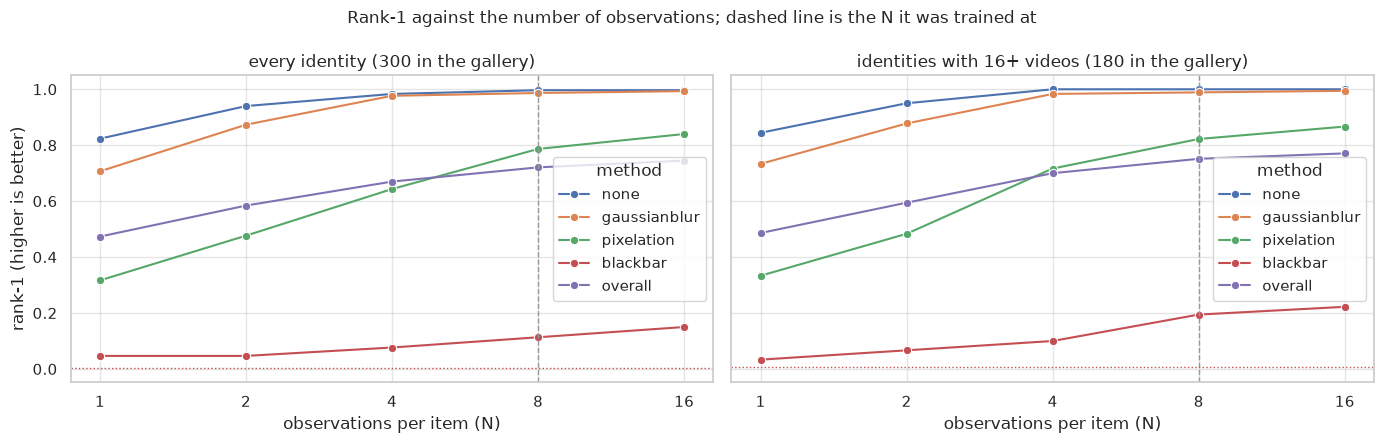

In [4]:
order = [*CURRICULUM, "overall"]
fig, axes = plt.subplots(1, len(populations), figsize=(7 * len(populations), 4.5), sharey=True)

for axis, (population, people) in zip(np.atleast_1d(axes), populations.items()):
    shown = curve[curve["population"] == population]
    sns.lineplot(shown, x="frames", y="rank1", hue="method", hue_order=order, marker="o", ax=axis)
    axis.axvline(TRAINED_AT, color="#999999", linestyle="--", linewidth=1)
    axis.axhline(1 / len(people), color="#C44E52", linestyle=":", linewidth=1)
    axis.set_xscale("log", base=2)
    axis.set_xticks(COUNTS, [str(count) for count in COUNTS])
    axis.set_title(f"{population} ({len(people)} in the gallery)")
    axis.set_xlabel("observations per item (N)")
    axis.set_ylabel("rank-1 (higher is better)")

fig.suptitle("Rank-1 against the number of observations; dashed line is the N it was trained at", fontsize=12)
fig.tight_layout()
plt.show()

What to read off it:

- **A rising curve past the trained N** means the model generalises beyond what it was trained on, and that more observations are worth having at inference even without retraining.
- **A curve that flattens before the trained N** means the extra observations are not being used, and the limit is the aggregator rather than the evidence.
- **A gap between the two populations** separates distinct sightings from repeated ones. If the restricted curve keeps climbing where the full one flattens, the flattening is identities running out of videos, not the method running out of value.